In [32]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
from tensorflow.keras import datasets, layers, models


In [33]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = r"C:\Users\ASUS\OneDrive\Desktop\KK cats_and_dogs_filtered\train"
val_dir   = r"C:\Users\ASUS\OneDrive\Desktop\KK cats_and_dogs_filtered\validation"

train_ds = image_dataset_from_directory(
    train_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

val_ds = image_dataset_from_directory(
    val_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)
# ✅ SAVE CLASS NAMES HERE
class_names = train_ds.class_names
print("Classes:", class_names)

Found 500 files belonging to 2 classes.
Found 126 files belonging to 2 classes.
Classes: ['cats', 'dogs']


In [34]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds   = val_ds.map(lambda x, y: (normalization_layer(x), y))


In [35]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)


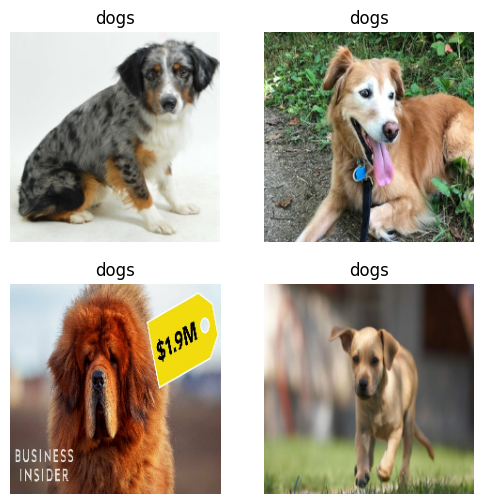

In [36]:

for images, labels in train_ds.take(1):
    plt.figure(figsize=(6,6))
    for i in range(4):
        plt.subplot(2,2,i+1)
        plt.imshow(images[i])
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
    plt.show()


In [37]:
# model = models.Sequential()

# # Convolution Layer 1
# model.add(layers.Conv2D(32, (3, 3), activation='relu',
#                         input_shape=(224, 224, 3)))
# model.add(layers.MaxPooling2D((2, 2)))

# # Convolution Layer 2
# model.add(layers.Conv2D(64, (3, 3), activation='relu'))
# model.add(layers.MaxPooling2D((2, 2)))

# # Convolution Layer 3
# model.add(layers.Conv2D(64, (3, 3), activation='relu'))

# # Fully Connected Layers
# model.add(layers.Flatten())
# model.add(layers.Dense(64, activation='relu'))
# model.add(layers.Dense(1, activation='sigmoid'))


# model.compile(
#     optimizer='adam',
#     loss='binary_crossentropy',
#     metrics=['accuracy']
# )

# history = model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=10
# )


In [38]:
from tensorflow.keras.applications import VGG19
from tensorflow.keras import layers, models

base_model = VGG19(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# ❄️ Freeze VGG19 layers
base_model.trainable = False


model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])


model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)




80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 145s 9s/step - accuracy: 0.5471 - loss: 0.7275 - val_accuracy: 0.7143 - val_loss: 0.6023
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 140s 9s/step - accuracy: 0.6974 - loss: 0.5705 - val_accuracy: 0.8016 - val_loss: 0.5361
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 140s 9s/step - accuracy: 0.7719 - loss: 0.4778 - val_accuracy: 0.7778 - val_loss: 0.5236
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 139s 9s/step - accuracy: 0.8025 - loss: 0.4456 - val_accuracy: 0.7937 - val_loss: 0.4689
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 140s 9s/step - accuracy: 0.8427 - loss: 0.3697 - val_accuracy: 0.7857 - val_loss: 0.4539
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 141s 9s/step - accuracy: 0.8385 - loss: 0.3905 - val_accuracy: 0.7857 - val_loss: 0.4433
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 174s 11s/step - accuracy: 0.8725 - loss: 0.3185 - val_accuracy: 0.7857 - val_loss: 0.4219
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 249s 16s/step - accur

In [39]:
test_loss, test_accuracy = model.evaluate(val_ds)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy*100:.2f}%")


4/4 ━━━━━━━━━━━━━━━━━━━━ 33s 8s/step - accuracy: 0.8114 - loss: 0.3933
Test Loss     : 0.3880
Test Accuracy : 82.54%


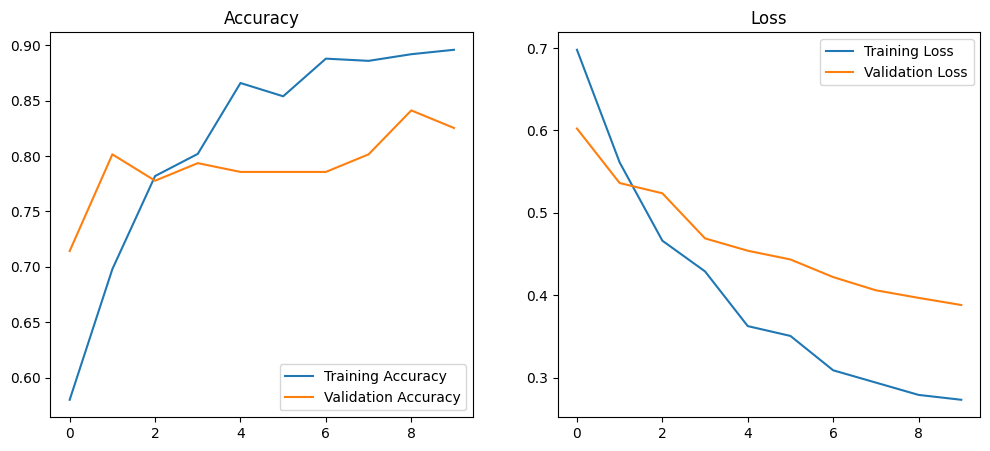

In [40]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()


In [41]:
import numpy as np
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\ASUS\Downloads\cat1.jpg" # change this

img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)


In [42]:
prediction = model.predict(img_array)[0][0]

if prediction > 0.5:
    print("Prediction: DOG 🐶")
else:
    print("Prediction: CAT 🐱")

print("Confidence:", prediction)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step
Prediction: CAT 🐱
Confidence: 0.096240915


In [43]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=class_names))


1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
[[51 12]
 [10 53]]
              precision    recall  f1-score   support

        cats       0.84      0.81      0.82        63
        dogs       0.82      0.84      0.83        63

    accuracy                           0.83       126
   macro avg       0.83      0.83      0.83       126
weighted avg       0.83      0.83      0.83       126

